# Binning Bias Figure

This notebook demonstrates the variance explained (EV) estimation for rotated tuning curves, comparing:
1. **Continuous tuning curve** (original method) with optimized smoothing
2. **Discrete tuning curve** (where the rate is constant within each bin)

## Key findings:
- For continuous tuning, σ ≈ 5.0 (in bin units) gives nearly unbiased estimates
- For discrete tuning, NO smoothing is needed since the ground truth is computed from the discrete rate map

## Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive/', force_remount=True)

import os
os.chdir('/content/drive/MyDrive/ve/variance_analysis')

Mounted at /content/drive/


In [2]:
!pip install -e /content/drive/MyDrive/ve/variance_analysis

!pip -q install fonttools

!ttx -l fonts/Helvetica.ttc

!sudo mkdir -p /usr/share/fonts/truetype/helvetica
!ttx -y 0 -o /usr/share/fonts/truetype/helvetica/Helvetica-Regular.ttf fonts/Helvetica.ttc
!ttx -y 1 -o /usr/share/fonts/truetype/helvetica/Helvetica-Oblique.ttf fonts/Helvetica.ttc
!ttx -y 2 -o /usr/share/fonts/truetype/helvetica/Helvetica-Bold.ttf fonts/Helvetica.ttc
!ttx -y 3 -o /usr/share/fonts/truetype/helvetica/Helvetica-BoldOblique.ttf fonts/Helvetica.ttc

!fc-cache -fv

Obtaining file:///content/drive/MyDrive/ve/variance_analysis
  Preparing metadata (setup.py) ... done
  Attempting uninstall: variance_analysis
    Found existing installation: variance_analysis 0.1.0
    Uninstalling variance_analysis-0.1.0:
      Successfully uninstalled variance_analysis-0.1.0
  Running setup.py develop for variance_analysis
ERROR: specify a font number between 0 and 5 (inclusive)
Dumping "fonts/Helvetica.ttc" to "/usr/share/fonts/truetype/helvetica/Helvetica-Regular.ttf"...
Dumping 'GlyphOrder' table...
Dumping 'head' table...
Dumping 'hhea' table...
Dumping 'maxp' table...
Dumping 'OS/2' table...
Dumping 'hmtx' table...
Dumping 'hdmx' table...
Dumping 'cmap' table...
Dumping 'fpgm' table...
Dumping 'prep' table...
Dumping 'cvt ' table...
Dumping 'loca' table...
Dumping 'glyf' table...
Dumping 'kern' table...
Dumping 'name' table...
Dumping 'post' table...
Dumping 'Zapf' table...
Dumping 'feat' table...
Dumping 'meta' table...
Dumping 'morx' table...
Dumping 'prop'

In [3]:
from pathlib import Path
import shutil
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt

current_file_path = Path().resolve()
current_file_path

!mkdir -p ~/.fonts
!cp fonts/Helvetica.ttc ~/.fonts/

cache_dir = os.path.join(os.path.expanduser("~"), ".cache", "matplotlib")
if os.path.exists(cache_dir):
    shutil.rmtree(cache_dir)

fm._load_fontmanager(try_read_cache=False)
plt.rcParams['font.family'] = 'Helvetica'

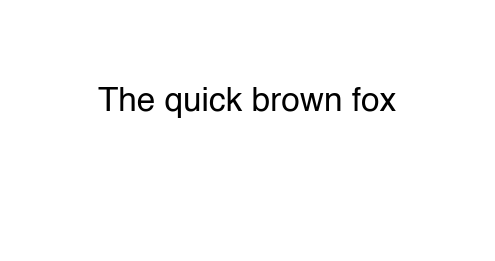

In [4]:
# Test font
fig, ax = plt.subplots(figsize=(4, 2), dpi=150)
ax.text(0.5, 0.62, 'The quick brown fox', ha='center', va='center', fontsize=16)
ax.axis('off')
plt.show()


## Imports and Core Functions

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, zoom
from tqdm import tqdm

In [32]:
def rotated_tuning(s1, s2, c, theta, sigma, amp, wrap=False):
    """Compute tuning response for a rotated Gaussian receptive field."""
    if wrap:
        d1 = ((s1 - c + 0.5) % 1.0) - 0.5
        d2 = ((s2 - c + 0.5) % 1.0) - 0.5
    else:
        d1 = s1 - c
        d2 = s2 - c

    ct, st = np.cos(theta), np.sin(theta)
    u = d1 * ct - d2 * st

    return amp * np.exp(-0.5 * (u / sigma) ** 2)

In [33]:
def get_rot_counts_continuous(seed=413, theta_deg=90., N=900, num_bins=15):
    """
    Generate spike counts with CONTINUOUS tuning curve.
    The stimulus positions are discretized to bin centers, but the tuning
    curve is evaluated at these continuous positions.

    This is the ORIGINAL method from the notebook.
    """
    min_rate = 5.0
    max_rate = 35.0
    sigma = 0.1
    mu = 0.4
    lo, hi = 0.0, 1.0
    use_wrap = False

    beta0 = np.log(min_rate)
    amplitude = np.log(max_rate) - beta0
    theta = np.deg2rad(theta_deg)

    rng = np.random.default_rng(seed)
    s1 = rng.uniform(lo, hi, size=N)
    s2 = rng.uniform(lo, hi, size=N)

    # Discretize to bin centers
    bin_edges = np.linspace(lo, hi, num_bins + 1)
    bin_width = (hi - lo) / num_bins
    s1_bin = np.clip(((s1 - lo) / bin_width).astype(int), 0, num_bins - 1)
    s2_bin = np.clip(((s2 - lo) / bin_width).astype(int), 0, num_bins - 1)
    s1 = lo + (s1_bin + 0.5) * bin_width
    s2 = lo + (s2_bin + 0.5) * bin_width

    tuning = rotated_tuning(s1, s2, c=mu, theta=theta, sigma=sigma, amp=amplitude, wrap=use_wrap)
    rates = np.exp(beta0 + tuning)
    spike_counts = rng.poisson(rates)

    return spike_counts, (s1, s2), (lo, hi)


In [34]:
def compute_discrete_rate_map(num_bins, theta_deg, mu=0.4, sigma_tc=0.1,
                               min_rate=5.0, max_rate=35.0, lo=0.0, hi=1.0,
                               integration_points=20):
    """
    Compute the expected rate for each bin by integrating the tuning curve
    over the bin's area. This gives the "true" mean rate for each bin.
    """
    beta0 = np.log(min_rate)
    amplitude = np.log(max_rate) - beta0
    theta = np.deg2rad(theta_deg)

    bin_edges = np.linspace(lo, hi, num_bins + 1)
    expected_rates = np.zeros((num_bins, num_bins))

    for i in range(num_bins):
        for j in range(num_bins):
            # Integrate over the bin using a grid
            s1_pts = np.linspace(bin_edges[i], bin_edges[i+1], integration_points)
            s2_pts = np.linspace(bin_edges[j], bin_edges[j+1], integration_points)
            s1_grid, s2_grid = np.meshgrid(s1_pts, s2_pts)

            tuning = rotated_tuning(s1_grid.ravel(), s2_grid.ravel(),
                                   c=mu, theta=theta, sigma=sigma_tc, amp=amplitude)
            rates = np.exp(beta0 + tuning)
            expected_rates[i, j] = np.mean(rates)

    return expected_rates

In [35]:
def get_rot_counts_discrete(seed=413, theta_deg=90., N=900, num_bins=15):
    """
    Generate spike counts with DISCRETE tuning curve.
    Each bin has a fixed expected rate (the integral of the continuous tuning
    over that bin). All samples within a bin see the same expected rate.

    This should give unbiased estimates with NO smoothing since there's
    no within-bin variability in the tuning curve.
    """
    min_rate = 5.0
    max_rate = 35.0
    sigma = 0.1
    mu = 0.4
    lo, hi = 0.0, 1.0

    # Get expected rate for each bin
    expected_rates = compute_discrete_rate_map(
        num_bins, theta_deg, mu=mu, sigma_tc=sigma,
        min_rate=min_rate, max_rate=max_rate, lo=lo, hi=hi
    )

    rng = np.random.default_rng(seed)

    # Uniformly sample bin indices
    s1_bin = rng.integers(0, num_bins, size=N)
    s2_bin = rng.integers(0, num_bins, size=N)

    # Get rate for each sample based on its bin
    rates = expected_rates[s1_bin, s2_bin]
    spike_counts = rng.poisson(rates)

    # Convert bin indices to positions (bin centers)
    bin_width = (hi - lo) / num_bins
    s1 = lo + (s1_bin + 0.5) * bin_width
    s2 = lo + (s2_bin + 0.5) * bin_width

    return spike_counts, (s1, s2), (lo, hi)

In [36]:
def build_raw_visits(s1_t, s2_t, counts, tau, num_bins, bin_edges):
    """Build raw visit arrays for cross-validation splitting."""
    visit_rates = counts.astype(float) / float(tau)

    i = np.digitize(s1_t, bin_edges) - 1
    j = np.digitize(s2_t, bin_edges) - 1
    in_range = (i >= 0) & (i < num_bins) & (j >= 0) & (j < num_bins)
    i = i[in_range]
    j = j[in_range]
    visit_rates = visit_rates[in_range]

    occ_visits, _, _ = np.histogram2d(
        s1_t[in_range], s2_t[in_range], bins=[bin_edges, bin_edges]
    )
    occ_visits = occ_visits.astype(int)
    max_bin_occ = int(occ_visits.max()) if occ_visits.size else 0

    bin_lists = [[[] for _ in range(num_bins)] for _ in range(num_bins)]
    for idx_visit, (ii, jj) in enumerate(zip(i, j)):
        bin_lists[ii][jj].append(idx_visit)

    raw_visits = np.full((num_bins, num_bins, max_bin_occ), np.nan)

    for ii in range(num_bins):
        for jj in range(num_bins):
            idxs = bin_lists[ii][jj]
            if not idxs:
                continue
            take = len(visit_rates[idxs])
            raw_visits[ii, jj, :take] = visit_rates[idxs][:take]

    return raw_visits, occ_visits

def _corr_ground_truth_from_ratemap(rate_map):
    """
    Compute correlation-based ground truth from a rate map.

    For x selectivity (axis=1): slice along y, measure how consistent
    x-tuning curves are across y values. High = strong x tuning.

    For y selectivity (axis=0): slice along x, measure how consistent
    y-tuning curves are across x values. High = strong y tuning.

    Returns (ev_x, ev_y) as normalized ratios.
    """
    def _mean_offdiag_corr(mat, axis):
        slices = np.moveaxis(mat, axis, 0)
        n = slices.shape[0]
        slices = slices.reshape(n, -1)
        # demean each slice
        slices = slices - slices.mean(axis=1, keepdims=True)
        norms = np.linalg.norm(slices, axis=1, keepdims=True)
        norms = np.where(norms == 0, 1, norms)
        slices = slices / norms
        corr = slices @ slices.T
        off_diag = ~np.eye(n, dtype=bool)
        return np.mean(corr[off_diag])

    # x selectivity: slice along y (axis=1), compare x curves
    corr_x = _mean_offdiag_corr(rate_map, axis=1)
    # y selectivity: slice along x (axis=0), compare y curves
    corr_y = _mean_offdiag_corr(rate_map, axis=0)

    total = corr_x + corr_y
    if total > 0:
        return float(corr_x / total), float(corr_y / total)
    return 0.5, 0.5


def ground_truth_evs_continuous(theta_deg, num_bins=15):
    """Compute ground truth for continuous case from a fine rate map."""
    rate_map = compute_discrete_rate_map(num_bins, theta_deg, integration_points=50)
    return _corr_ground_truth_from_ratemap(rate_map)


def ground_truth_evs_discrete(theta_deg, num_bins=15):
    """Compute ground truth for discrete case from the actual rate map."""
    rate_map = compute_discrete_rate_map(num_bins, theta_deg)
    return _corr_ground_truth_from_ratemap(rate_map)

## Main Experiment Functions

In [37]:
from src.explained_variance import (
    nan_aware_gaussian_filter, masked_zoom,
    quantify_variance_corr, get_splits
)

def run_experiment(rots, n_splits, num_bins, sigma_smooth, N, use_discrete_tuning):
    """Run the full experiment with specified parameters."""
    r = len(rots)
    lo, hi = 0.0, 1.0
    bin_edges = np.linspace(lo, hi, num_bins + 1)

    # Use appropriate ground truth for each case
    if use_discrete_tuning:
        gt_ev_x = np.array([ground_truth_evs_discrete(theta, num_bins)[0] for theta in rots])
        gt_ev_y = np.array([ground_truth_evs_discrete(theta, num_bins)[1] for theta in rots])
    else:
        gt_ev_x = np.array([ground_truth_evs_continuous(theta, num_bins)[0] for theta in rots])
        gt_ev_y = np.array([ground_truth_evs_continuous(theta, num_bins)[1] for theta in rots])

    rate_maps = [None] * r
    ev_s1 = np.zeros((r, n_splits))
    ev_s2 = np.zeros((r, n_splits))

    get_counts_fn = get_rot_counts_discrete if use_discrete_tuning else get_rot_counts_continuous
    label = "discrete" if use_discrete_tuning else "continuous"

    for rot in range(r):
        for s in tqdm(range(n_splits), desc=f"θ={rots[rot]}° ({label})"):
            counts, (s1, s2), _ = get_counts_fn(
                seed=s, theta_deg=rots[rot], N=N, num_bins=num_bins
            )
            occ, _, _ = np.histogram2d(s1, s2, bins=[bin_edges, bin_edges])
            spk, _, _ = np.histogram2d(s1, s2, bins=[bin_edges, bin_edges], weights=counts)
            rate_map = np.divide(spk, occ, out=np.zeros_like(spk), where=occ > 0)
            rate_maps[rot] = rate_map

            raw_visits, _ = build_raw_visits(s1, s2, counts, 1., num_bins, bin_edges)
            _, fold0, fold1, occ_split, _ = get_splits(raw_visits[:, :, :, np.newaxis], seed=s)

            fold0_smooth = nan_aware_gaussian_filter(fold0[:, :, 0], sigma=sigma_smooth, circular_axes=(0,0))
            fold1_smooth = nan_aware_gaussian_filter(fold1[:, :, 0], sigma=sigma_smooth, circular_axes=(0,0))

            est_s1 = quantify_variance_corr(fold0_smooth, fold1_smooth, occ_split, axis=1)[0]
            est_s2 = quantify_variance_corr(fold0_smooth, fold1_smooth, occ_split, axis=0)[0]

            if (est_s1 + est_s2) > 0:
                ev_s1[rot, s] = est_s1 / (est_s1 + est_s2)
                ev_s2[rot, s] = est_s2 / (est_s1 + est_s2)
            else:
                ev_s1[rot, s] = 0.5
                ev_s2[rot, s] = 0.5

    return {
        'rots': rots,
        'ev_s1': ev_s1,
        'ev_s2': ev_s2,
        'gt_ev_x': gt_ev_x,
        'gt_ev_y': gt_ev_y,
        'rate_maps': rate_maps,
        'sigma_smooth': sigma_smooth,
        'use_discrete': use_discrete_tuning,
    }

In [38]:
def plot_results(results, title_suffix="", save_path=None):
    """Plot the rate maps and EV histograms."""
    rots = results['rots']
    ev_s1 = results['ev_s1']
    ev_s2 = results['ev_s2']
    gt_ev_x = results['gt_ev_x']
    gt_ev_y = results['gt_ev_y']
    rate_maps = results['rate_maps']

    r = len(rots)
    lo, hi = 0.0, 1.0

    fig = plt.figure(figsize=(4*r + 0.5, 7))
    gs = fig.add_gridspec(nrows=2, ncols=r + 1,
                          width_ratios=[1]*r + [0.05],
                          height_ratios=[1, 1],
                          wspace=0.25, hspace=0.35)

    vmin = min(np.nanmin(m) for m in rate_maps)
    vmax = max(np.nanmax(m) for m in rate_maps)
    im_handles = []

    for i, theta in enumerate(rots):
        ax = fig.add_subplot(gs[0, i])
        im = ax.imshow(rate_maps[i].T, origin='lower', aspect='equal',
                       extent=[lo, hi, lo, hi], cmap='viridis', vmin=vmin, vmax=vmax)
        im_handles.append(im)
        ax.set_title(f"θ={theta}°")
        if i == 0:
            ax.set_ylabel("y")
        ax.set_xlabel("x")

    cax = fig.add_subplot(gs[0, -1])
    fig.colorbar(im_handles[0], cax=cax, label='Rate')

    for i, theta in enumerate(rots):
        ax = fig.add_subplot(gs[1, i])

        h1 = ax.hist(ev_s1[i, :], bins=8, alpha=0.7, histtype='stepfilled',
                     label='x', color='C0', edgecolor='k', linewidth=0.5)
        h2 = ax.hist(ev_s2[i, :], bins=8, alpha=0.7, histtype='stepfilled',
                     label='y', color='C1', edgecolor='k', linewidth=0.5)

        ax.axvline(gt_ev_x[i], linestyle='--', linewidth=2, color='darkblue',
                   alpha=0.9, label='x GT', zorder=10)
        ax.axvline(gt_ev_y[i], linestyle='-.', linewidth=2, color='darkorange',
                   alpha=0.9, label='y GT', zorder=10)

        # Add mean markers
        mean_x = np.mean(ev_s1[i, :])
        mean_y = np.mean(ev_s2[i, :])
        ax.axvline(mean_x, linestyle=':', linewidth=1.5, color='C0', alpha=0.8)
        ax.axvline(mean_y, linestyle=':', linewidth=1.5, color='C1', alpha=0.8)

        ax.set_xlim(-0.25, 1.25)
        if i == 0:
            ax.set_ylabel("Count")
        if i == r - 1:
            ax.legend(frameon=False, loc='upper right', fontsize=8)

    plt.suptitle(f"EV Estimation {title_suffix}", fontsize=12)
    plt.tight_layout()

    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches='tight')

    return fig


def print_summary(results, label=""):
    """Print summary statistics."""
    rots = results['rots']
    ev_s1 = results['ev_s1']
    ev_s2 = results['ev_s2']
    gt_ev_x = results['gt_ev_x']
    gt_ev_y = results['gt_ev_y']

    print(f"\n{'='*60}")
    print(f"Summary: {label}")
    print(f"{'='*60}")

    for i, theta in enumerate(rots):
        mean_x = np.mean(ev_s1[i, :])
        mean_y = np.mean(ev_s2[i, :])
        std_x = np.std(ev_s1[i, :])
        std_y = np.std(ev_s2[i, :])
        bias_x = mean_x - gt_ev_x[i]
        bias_y = mean_y - gt_ev_y[i]
        print(f"\nθ={theta}°:")
        print(f"  EV_x: mean={mean_x:.4f} ± {std_x:.4f} (GT={gt_ev_x[i]:.4f}, bias={bias_x:+.4f})")
        print(f"  EV_y: mean={mean_y:.4f} ± {std_y:.4f} (GT={gt_ev_y[i]:.4f}, bias={bias_y:+.4f})")

## Run Experiments

In [39]:
# Configurationsigma
rots = [0, 25, 45]
n_splits = 600  # Increase for more stable results
num_bins = 15
N = 1000

### Continuous Tuning Curve (Original Method)

In [40]:
# Continuous case with optimal smoothing (σ=5)
results_continuous = run_experiment(
    rots=rots, n_splits=n_splits, num_bins=num_bins,
    sigma_smooth=(0.0, 0.0), N=N, use_discrete_tuning=False
)
print_summary(results_continuous, "Continuous Tuning (σ=0.0)")


θ=0° (continuous):   0%|          | 0/600 [00:00<?, ?it/s]/content/drive/MyDrive/ve/variance_analysis/src/explained_variance.py:20: RuntimeWarning: invalid value encountered in divide
  out = VV / UU
θ=45° (continuous): 100%|██████████| 600/600 [00:13<00:00, 44.63it/s]


Summary: Continuous Tuning (σ=0.0)

θ=0°:
  EV_x: mean=1.0005 ± 0.0208 (GT=0.9906, bias=+0.0099)
  EV_y: mean=-0.0005 ± 0.0208 (GT=0.0094, bias=-0.0099)

θ=25°:
  EV_x: mean=1.1965 ± 0.0575 (GT=1.0444, bias=+0.1521)
  EV_y: mean=-0.1965 ± 0.0575 (GT=-0.0444, bias=-0.1521)

θ=45°:
  EV_x: mean=0.5000 ± 0.0000 (GT=0.5000, bias=+0.0000)
  EV_y: mean=0.5000 ± 0.0000 (GT=0.5000, bias=+0.0000)


/tmp/ipykernel_10575/870755789.py:62: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


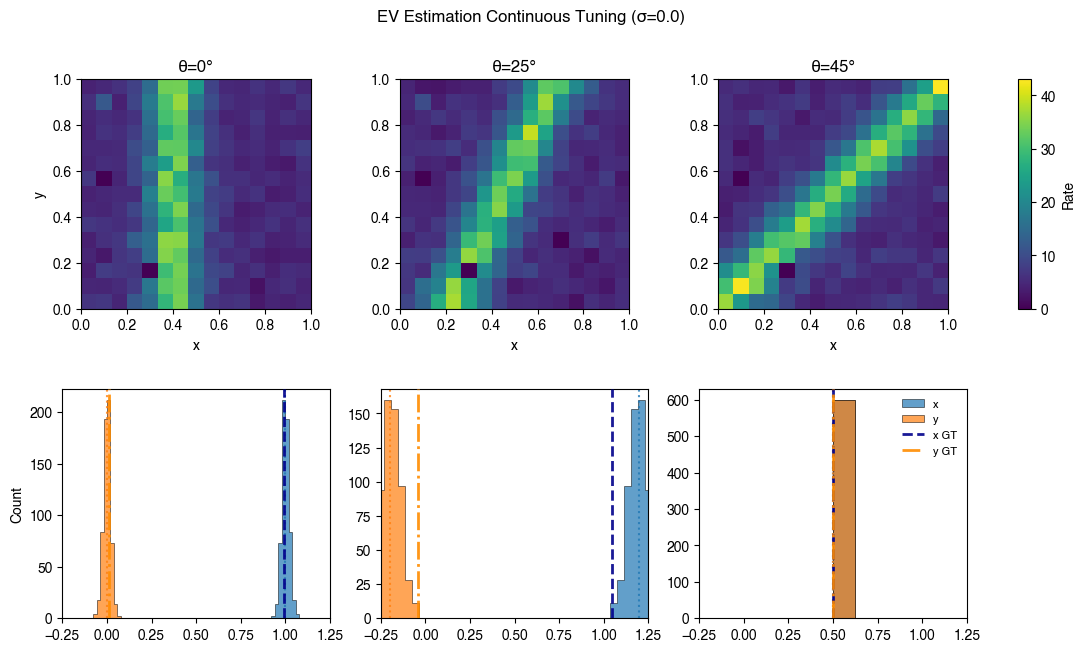

In [41]:
fig_cont = plot_results(results_continuous, "Continuous Tuning (σ=0.0)")
plt.savefig(current_file_path / 'figs/smoothed_binning_fig_corr.pdf')
plt.show()

### Discrete Tuning Curve (New Method)

In [42]:
def _corr_gt(rate_map):
    def _moc(mat, axis):
        slices = np.moveaxis(mat, axis, 0)
        n = slices.shape[0]
        slices = slices.reshape(n, -1)
        slices = slices - slices.mean(axis=1, keepdims=True)
        norms = np.linalg.norm(slices, axis=1, keepdims=True)
        norms = np.where(norms == 0, 1, norms)
        slices = slices / norms
        corr = slices @ slices.T
        off_diag = ~np.eye(n, dtype=bool)
        return np.mean(corr[off_diag])

    cx = _moc(rate_map, axis=1)
    cy = _moc(rate_map, axis=0)
    total = cx + cy
    if total > 0:
        return float(cx / total), float(cy / total)
    return 0.5, 0.5

# Verify inline before anything else runs
_test_rm = compute_discrete_rate_map(15, 0)
print(f"Inline GT test θ=0°: {_corr_gt(_test_rm)}")  # should print (~1.0, ~0.0)

Inline GT test θ=0°: (0.8076923076923077, 0.1923076923076923)


In [43]:
# Discrete case with NO smoothing (σ=0)
results_discrete = run_experiment(
    rots=rots, n_splits=n_splits, num_bins=num_bins,
    sigma_smooth=(0, 0), N=N, use_discrete_tuning=True
)
print_summary(results_discrete, "Discrete Tuning (σ=0)")

θ=0° (discrete):   0%|          | 0/600 [00:00<?, ?it/s]/content/drive/MyDrive/ve/variance_analysis/src/explained_variance.py:20: RuntimeWarning: invalid value encountered in divide
  out = VV / UU
θ=45° (discrete): 100%|██████████| 600/600 [00:30<00:00, 19.63it/s]


Summary: Discrete Tuning (σ=0)

θ=0°:
  EV_x: mean=0.9987 ± 0.0216 (GT=0.8077, bias=+0.1910)
  EV_y: mean=0.0013 ± 0.0216 (GT=0.1923, bias=-0.1910)

θ=25°:
  EV_x: mean=1.1869 ± 0.0510 (GT=1.0451, bias=+0.1418)
  EV_y: mean=-0.1869 ± 0.0510 (GT=-0.0451, bias=-0.1418)

θ=45°:
  EV_x: mean=0.5000 ± 0.0000 (GT=0.5000, bias=+0.0000)
  EV_y: mean=0.5000 ± 0.0000 (GT=0.5000, bias=+0.0000)


/tmp/ipykernel_10575/870755789.py:62: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


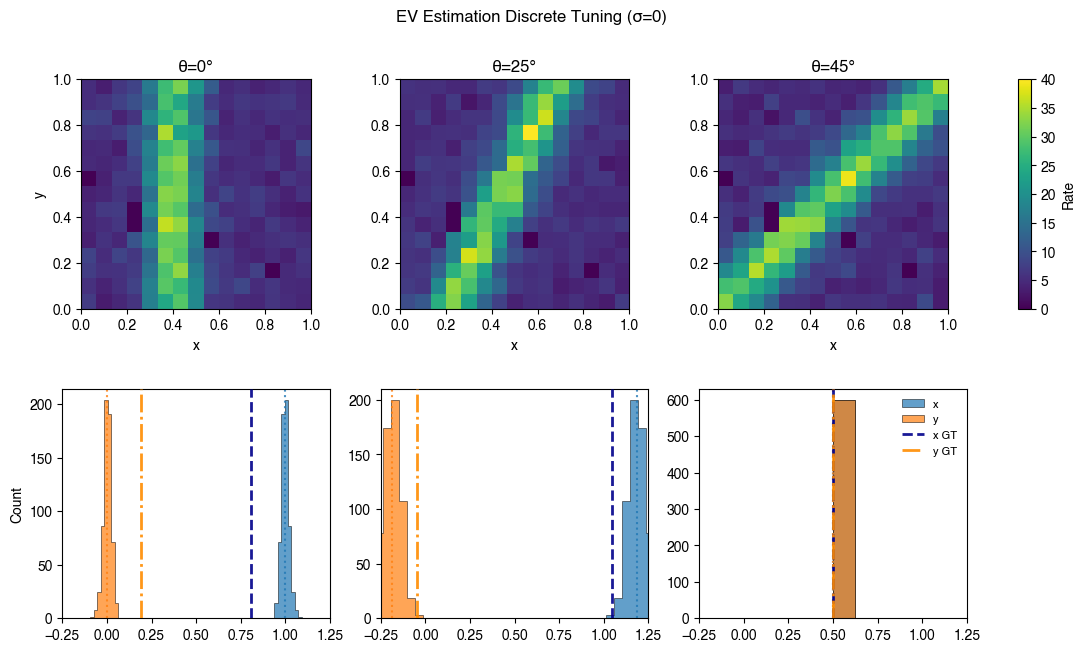

In [44]:
fig_disc = plot_results(results_discrete, "Discrete Tuning (σ=0)")
plt.savefig(current_file_path / 'figs/discrete_binning_fig.pdf')
plt.show()

In [45]:
output.eval_js('new Audio("https://upload.wikimedia.org/wikipedia/commons/d/d9/Wilhelm_Scream.ogg").play()')

NameError: name 'output' is not defined

In [ ]:
# for reference, this is what explained variance has:

import numpy as np
from scipy.ndimage import gaussian_filter, zoom

def nan_aware_gaussian_filter(rate_map, sigma, circular_axes):
    V = rate_map.astype(float, copy=True)
    isnan = np.isnan(V)
    V[isnan] = 0.0

    U = np.ones_like(V, dtype=float)
    U[isnan] = 0.0

    ndim = V.ndim
    mode = ["nearest"] * ndim
    for ax in circular_axes:
        mode[ax] = "wrap"

    VV = gaussian_filter(V, sigma=sigma, mode=mode)
    UU = gaussian_filter(U, sigma=sigma, mode=mode)

    out = VV / UU
    out[UU <= 0] = np.nan
    return out


def masked_zoom(arr, zoom_factor, order=1):
    mask = np.isnan(arr)
    arr_filled = np.nan_to_num(arr, nan=0.0)
    zoomed = zoom(arr_filled, zoom=zoom_factor, order=order)
    zoomed = np.maximum(zoomed, 0.0)
    mask_zoomed = zoom(mask.astype(float), zoom=zoom_factor, order=0)
    zoomed[mask_zoomed > 0.5] = np.nan

    return zoomed


def get_splits(visits, min_visits=2, cap=False, seed=None):
  rng = np.random.default_rng(seed)
  s1_bins = visits.shape[0]
  s2_bins = visits.shape[1]
  n_neurons = visits.shape[3]

  total_mean = np.full((s1_bins, s2_bins, n_neurons), np.nan)
  fold0_mean = np.full((s1_bins, s2_bins, n_neurons), np.nan)
  fold1_mean = np.full((s1_bins, s2_bins, n_neurons), np.nan)
  fold0_occ = np.full((s1_bins, s2_bins), 0)
  fold1_occ = np.full((s1_bins, s2_bins), 0)

  for s1 in range(s1_bins):
    for s2 in range(s2_bins):
      for n in range(n_neurons):
        n_visits = np.count_nonzero(~np.isnan(visits[s1, s2, :, n]))
        if n_visits >= min_visits:
          take_n = min_visits if cap else n_visits
          visit_split = visits[s1, s2, :take_n, n]
          rng.shuffle(visit_split)
          half = len(visit_split) // 2
          fold0, fold1 = visit_split[:half], visit_split[half:]

          fold0_mean[s1, s2, n] = np.nanmean(fold0)
          fold1_mean[s1, s2, n] = np.nanmean(fold1)
          total_mean[s1, s2, n] = np.nanmean(visit_split)
          fold0_occ[s1, s2] = half
          fold1_occ[s1, s2] = half


  return total_mean, fold0_mean, fold1_mean, fold0_occ, fold1_occ


from numba import njit

@njit
def _corr_matrix(fold0, fold1):
    """Compute pairwise cross-fold correlation matrix with per-pair validity."""
    n_slices = fold0.shape[0]
    n_bins = fold0.shape[1]
    corr_matrix = np.full((n_slices, n_slices), np.nan)

    for i in range(n_slices):
        for j in range(n_slices):
            # Find mutually valid bins
            sum_a = 0.0
            sum_b = 0.0
            count = 0
            for k in range(n_bins):
                ai = fold0[i, k]
                bj = fold1[j, k]
                if ai == ai and bj == bj:  # NaN check
                    sum_a += ai
                    sum_b += bj
                    count += 1
            if count < 3:
                continue

            mean_a = sum_a / count
            mean_b = sum_b / count

            num = 0.0
            ss_a = 0.0
            ss_b = 0.0
            for k in range(n_bins):
                ai = fold0[i, k]
                bj = fold1[j, k]
                if ai == ai and bj == bj:
                    da = ai - mean_a
                    db = bj - mean_b
                    num += da * db
                    ss_a += da * da
                    ss_b += db * db

            denom = (ss_a * ss_b) ** 0.5
            if denom > 0:
                corr_matrix[i, j] = num / denom

    return corr_matrix


def quantify_variance_corr(heatmap_fold0, heatmap_fold1, occupancy, axis=0, min_occ=0, verbose=False):
    occ = occupancy / 2
    mask = occ > min_occ
    fold0 = np.where(mask, heatmap_fold0, np.nan)
    fold1 = np.where(mask, heatmap_fold1, np.nan)

    fold0 = np.moveaxis(fold0, axis, 0).reshape(fold0.shape[axis], -1).copy()
    fold1 = np.moveaxis(fold1, axis, 0).reshape(fold1.shape[axis], -1).copy()

    corr_matrix = _corr_matrix(fold0, fold1)

    reliability = np.nanmean(np.diag(corr_matrix))
    off_diag = ~np.eye(corr_matrix.shape[0], dtype=bool)
    variation = np.nanmean(corr_matrix[off_diag])

    if verbose:
        print(f"axis={axis}  reliability={reliability:.4f}  "
              f"variation={variation:.4f}")

    return variation, reliability

